In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Cargar imagen propia
img = cv2.imread("/content/descarga (2).jpg")
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
# Pasar a float para operar
img_f = img_rgb.astype(np.float32)

In [10]:
# Darken -> g(x) = f(x) - b
darken = img_f - 50

# Lighten -> g(x) = f(x) + b
lighten = img_f + 50

# Lower contrast (lineal) -> g(x) = a f(x), a<1
lower_contrast = 0.5 * img_f

# Raise contrast (lineal) -> g(x) = a f(x), a>1
raise_contrast = 1.5 * img_f

# Invert -> g(x) = 255 - f(x)
invert = 255 - img_f

# Non-linear lower contrast (gamma > 1)
gamma1 = 2.0
nonlinear_lower = 255 * (img_f/255) ** gamma1

# Non-linear raise contrast (gamma < 1)
gamma2 = 0.5
nonlinear_raise = 255 * (img_f/255) ** gamma2

In [11]:
# Recortar valores al rango [0,255]
darken = np.clip(darken,0,255).astype(np.uint8)
lighten = np.clip(lighten,0,255).astype(np.uint8)
lower_contrast = np.clip(lower_contrast,0,255).astype(np.uint8)
raise_contrast = np.clip(raise_contrast,0,255).astype(np.uint8)
invert = np.clip(invert,0,255).astype(np.uint8)
nonlinear_lower = np.clip(nonlinear_lower,0,255).astype(np.uint8)
nonlinear_raise = np.clip(nonlinear_raise,0,255).astype(np.uint8)

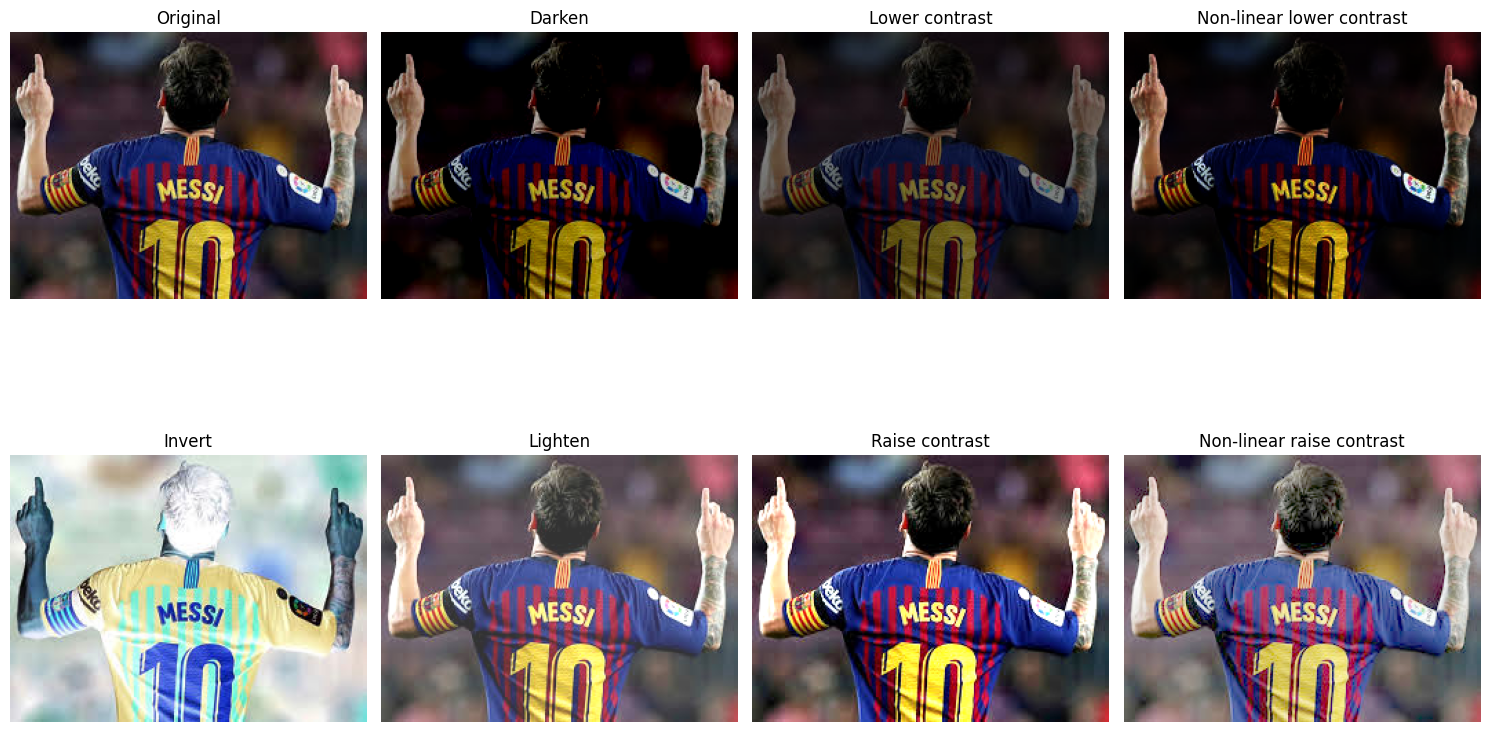

In [12]:
# Mostrar resultados
plt.figure(figsize=(15,10))

plt.subplot(2,4,1)
plt.imshow(img_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(2,4,2)
plt.imshow(darken)
plt.title("Darken")
plt.axis("off")

plt.subplot(2,4,3)
plt.imshow(lower_contrast)
plt.title("Lower contrast")
plt.axis("off")

plt.subplot(2,4,4)
plt.imshow(nonlinear_lower)
plt.title("Non-linear lower contrast")
plt.axis("off")

plt.subplot(2,4,5)
plt.imshow(invert)
plt.title("Invert")
plt.axis("off")

plt.subplot(2,4,6)
plt.imshow(lighten)
plt.title("Lighten")
plt.axis("off")

plt.subplot(2,4,7)
plt.imshow(raise_contrast)
plt.title("Raise contrast")
plt.axis("off")

plt.subplot(2,4,8)
plt.imshow(nonlinear_raise)
plt.title("Non-linear raise contrast")
plt.axis("off")

plt.tight_layout()
plt.show()

In [3]:
# -------------------------------
# 1) BOX FILTER (dos tamaños)
# -------------------------------
box_3 = cv2.blur(img_rgb, (3,3))
box_9 = cv2.blur(img_rgb, (9,9))

In [4]:
# -------------------------------
# 2) FILTRO GAUSSIANO (dos configs)
# -------------------------------
gauss_5_1 = cv2.GaussianBlur(img_rgb, (5,5), 1)
gauss_11_3 = cv2.GaussianBlur(img_rgb, (11,11), 3)

In [5]:
# Pasar a escala de grises para Sobel
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

In [6]:
# -------------------------------
# 3) SOBEL en X y en Y (sobre gris)
# -------------------------------
sobelx = cv2.Sobel(img_gray, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(img_gray, cv2.CV_64F, 0, 1, ksize=3)

# Magnitud del gradiente
grad_mag = np.sqrt(sobelx**2 + sobely**2)

# -------------------------------
# 4) Sobel directo vs Sobel con Gaussiano previo
# -------------------------------
gray_gauss = cv2.GaussianBlur(img_gray, (7,7), 2)

sobelx_smooth = cv2.Sobel(gray_gauss, cv2.CV_64F, 1, 0, ksize=3)
sobely_smooth = cv2.Sobel(gray_gauss, cv2.CV_64F, 0, 1, ksize=3)
grad_mag_smooth = np.sqrt(sobelx_smooth**2 + sobely_smooth**2)

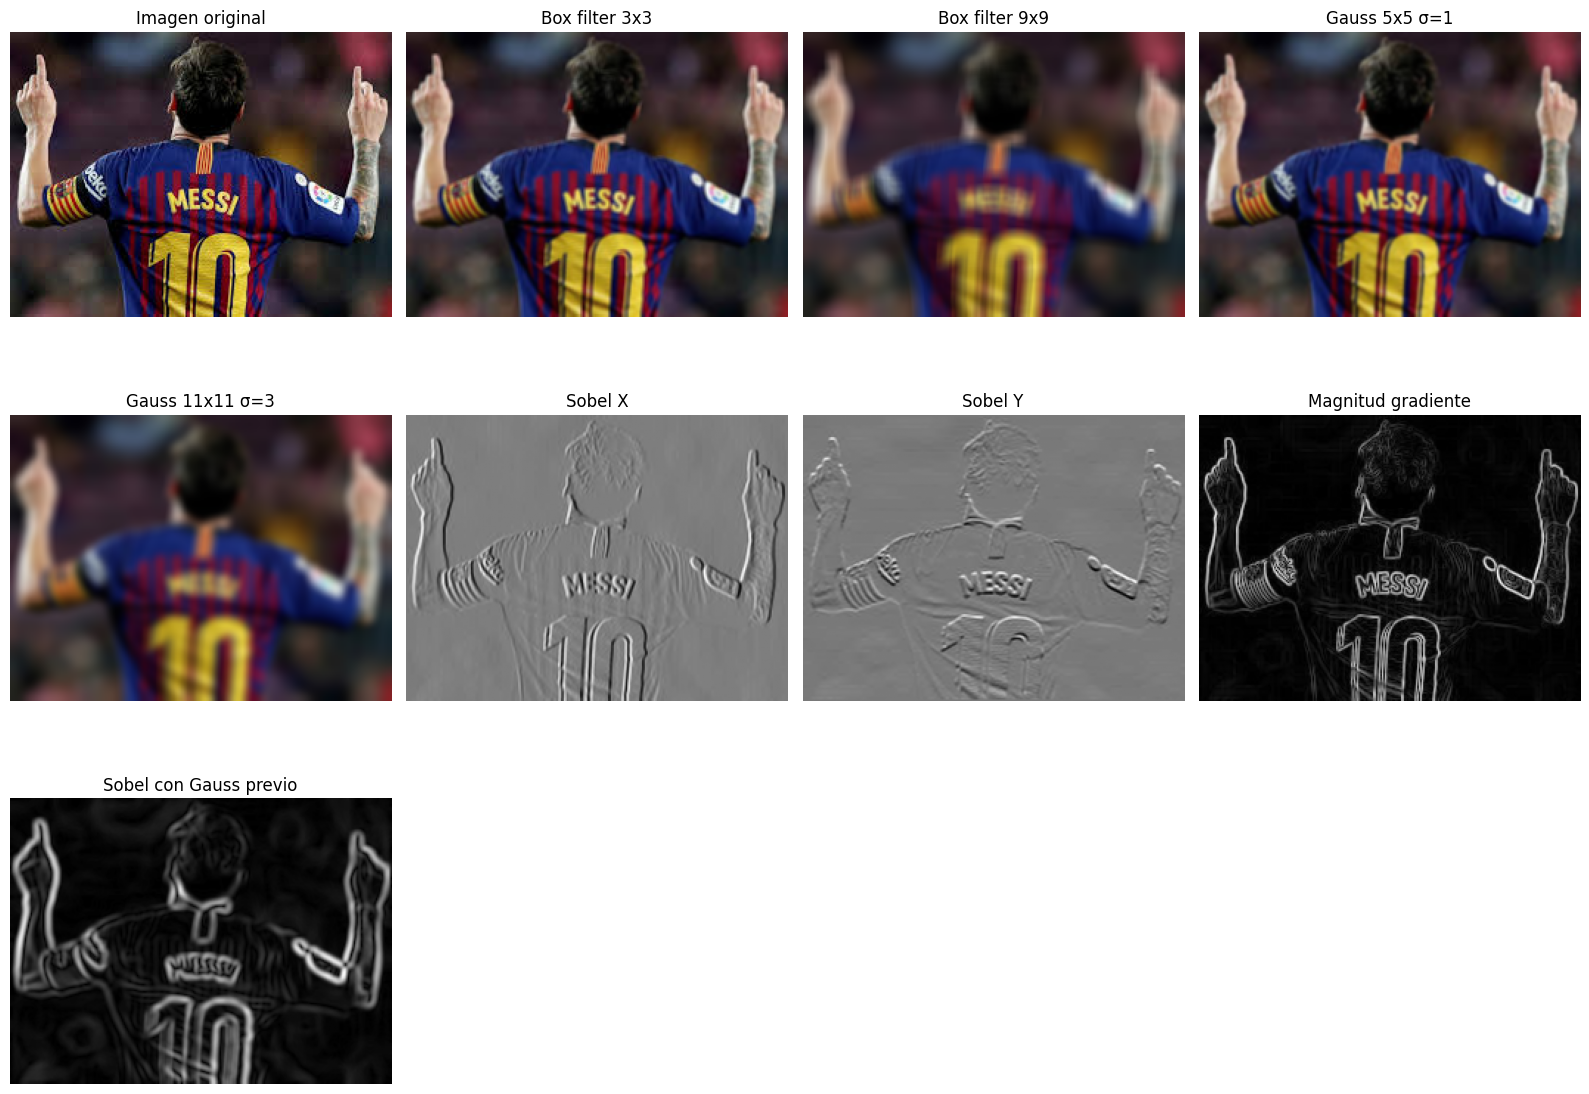

In [7]:
# -------------------------------
# Mostrar resultados
# -------------------------------
plt.figure(figsize=(16,12))

plt.subplot(3,4,1)
plt.imshow(img_rgb)
plt.title("Imagen original")
plt.axis("off")

plt.subplot(3,4,2)
plt.imshow(box_3)
plt.title("Box filter 3x3")
plt.axis("off")

plt.subplot(3,4,3)
plt.imshow(box_9)
plt.title("Box filter 9x9")
plt.axis("off")

plt.subplot(3,4,4)
plt.imshow(gauss_5_1)
plt.title("Gauss 5x5 σ=1")
plt.axis("off")

plt.subplot(3,4,5)
plt.imshow(gauss_11_3)
plt.title("Gauss 11x11 σ=3")
plt.axis("off")

plt.subplot(3,4,6)
plt.imshow(sobelx, cmap="gray")
plt.title("Sobel X")
plt.axis("off")

plt.subplot(3,4,7)
plt.imshow(sobely, cmap="gray")
plt.title("Sobel Y")
plt.axis("off")

plt.subplot(3,4,8)
plt.imshow(grad_mag, cmap="gray")
plt.title("Magnitud gradiente")
plt.axis("off")

plt.subplot(3,4,9)
plt.imshow(grad_mag_smooth, cmap="gray")
plt.title("Sobel con Gauss previo")
plt.axis("off")

plt.tight_layout()
plt.show()

### 1) ¿Qué efecto produce el box filter sobre la imagen?

El box filter produce un **suavizado general** de la imagen.  
Promedia los valores de los píxeles vecinos, haciendo que la imagen se vea más **borrosa** y con menos detalle fino.


### 2) ¿Qué diferencias se observan entre el box filter y el filtro Gaussiano?

El box filter promedia todos los píxeles por igual.  
El filtro Gaussiano le da **más peso a los píxeles centrales** y menos a los lejanos.

Por eso, el Gaussiano suaviza de forma **más natural** y conserva mejor las formas.

### 3) ¿Qué sucede al modificar el tamaño del kernel?

Al aumentar el tamaño del kernel:

- El suavizado es **más fuerte**
- Se pierden **más detalles**
- La imagen se ve **más borrosa**

### 4) ¿Qué tipo de detalle se pierde al suavizar la imagen?

Se pierden los **detalles finos**, las **texturas** y las pequeñas variaciones de intensidad.  
También se reducen los bordes más débiles.

### 5) ¿Qué bordes resalta Sobel en x y cuáles Sobel en y?

- **Sobel en X** resalta los bordes **verticales**.
- **Sobel en Y** resalta los bordes **horizontales**.


### 6) ¿Qué representa la magnitud del gradiente?

La magnitud del gradiente combina Sobel X y Sobel Y.  
Representa la **fuerza del cambio de intensidad** en cada píxel, es decir, dónde hay bordes sin importar la dirección.

### 7) ¿Qué sucede si se aplica Sobel sin suavizado previo?

Aparecen muchos bordes falsos producidos por el **ruido** y las pequeñas variaciones de la imagen.  
La detección es más **desordenada**.

### 8) ¿Por qué conviene aplicar un filtro Gaussiano antes de detectar bordes?

Porque elimina el ruido y las variaciones pequeñas.  
Así, Sobel detecta **bordes más limpios, definidos y reales**.